In [2]:
# Load and inspect the dataset
import pandas as pd
import numpy as np

df = pd.read_csv("networkTraffic.csv")
features = pd.read_csv("features.csv")
attack_map = pd.read_csv("attack_category_map.csv")

df = df.replace("?", np.nan)

print("Dataset shape:", df.shape)
print("Number of features:", df.shape[1] - 2)

print("\nTarget distribution:")
print(df["attack_cat"].value_counts().sort_index())

print("\nDuplicate records (excluding ID):")
print(df.drop(columns=["id"]).duplicated().sum())

print("\nDuplicate predictor patterns:")
print(df.drop(columns=["id", "attack_cat"]).duplicated().sum())


Dataset shape: (257673, 44)
Number of features: 42

Target distribution:
attack_cat
0    93000
1    13987
2     2329
3    16353
4    44525
5     2677
6    24246
7      174
8     1511
9    58871
Name: count, dtype: int64

Duplicate records (excluding ID):
94928

Duplicate predictor patterns:
103989


In [3]:

# Prepare predictors and target
from sklearn.model_selection import StratifiedGroupKFold

X = df.drop(columns=["id", "attack_cat"]).copy()
y = df["attack_cat"].copy()

# Identify identical predictor patterns
groups = pd.util.hash_pandas_object(X, index=False)

# Create a group-aware 80/20 split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Check the split
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())

# Check for identical patterns across sets
shared_groups = len(
    set(groups_train) & set(groups_test)
)

print("\nShared predictor patterns:", shared_groups)

# Investigate conflicting target labels
label_counts = df.groupby(groups)["attack_cat"].nunique()

print(
    "Patterns with conflicting labels:",
    (label_counts > 1).sum()
)


Training observations: 206254
Test observations: 51419

Training class distribution:
attack_cat
0    74485
1    11132
2     1861
3    13257
4    35846
5     2170
6    19278
7      137
8     1218
9    46870
Name: count, dtype: int64

Test class distribution:
attack_cat
0    18515
1     2855
2      468
3     3096
4     8679
5      507
6     4968
7       37
8      293
9    12001
Name: count, dtype: int64

Shared predictor patterns: 0
Patterns with conflicting labels: 2445


In [5]:
# Prepare the Random Forest preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import StratifiedGroupKFold
import time

categorical_features = ["proto", "service", "state"]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

rf_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Create a group-aware validation split from training data
val_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    val_splitter.split(X_train, y_train, groups_train)
)

X_fit = X_train.iloc[train_idx]
X_val = X_train.iloc[val_idx]

y_fit = y_train.iloc[train_idx]
y_val = y_train.iloc[val_idx]

print("Model training observations:", len(X_fit))
print("Validation observations:", len(X_val))

# Build the baseline Random Forest
rf_baseline = Pipeline([
    ("preprocessing", rf_preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
start_time = time.time()

rf_baseline.fit(X_fit, y_fit)

training_time = time.time() - start_time

# Evaluate the model
train_predictions = rf_baseline.predict(X_fit)
val_predictions = rf_baseline.predict(X_val)

print("\nBaseline Random Forest Results")
print("-" * 40)

print("Training macro F1:",
    round(f1_score(y_fit, train_predictions,
                    average="macro"), 4))

print("Validation accuracy:",
    round(accuracy_score(y_val, val_predictions), 4))

print("Validation macro F1:",
    round(f1_score(y_val, val_predictions,
                    average="macro"), 4))

print("Validation weighted F1:",
    round(f1_score(y_val, val_predictions,
                    average="weighted"), 4))

print("Training time:",
    round(training_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))


Model training observations: 154591
Validation observations: 51663

Baseline Random Forest Results
----------------------------------------
Training macro F1: 0.7729
Validation accuracy: 0.8275
Validation macro F1: 0.5382
Validation weighted F1: 0.8089
Training time: 116.04 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.92     18557
           1       0.93      0.80      0.86      3215
           2       0.93      0.08      0.14       478
           3       0.46      0.13      0.21      3277
           4       0.62      0.90      0.74      8964
           5       0.71      0.05      0.10       567
           6       0.67      0.57      0.62      4698
           7       0.67      0.11      0.19        36
           8       0.68      0.56      0.62       331
           9       1.00      0.97      0.99     11540

    accuracy                           0.83     51663
   macro avg       0.76      0.51      0.54

In [6]:
# Compare Random Forest with a single decision tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

tree_baseline = Pipeline([
    ("preprocessing", clone(rf_preprocessor)),
    ("tree", DecisionTreeClassifier(random_state=42))
])

# Train the decision tree
start_time = time.time()

tree_baseline.fit(X_fit, y_fit)

tree_training_time = time.time() - start_time

# Make predictions
tree_train_pred = tree_baseline.predict(X_fit)
tree_val_pred = tree_baseline.predict(X_val)

# Compare model performance
comparison = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Train Macro F1": f1_score(y_fit, tree_train_pred, average="macro"),
        "Validation Accuracy": accuracy_score(y_val, tree_val_pred),
        "Validation Macro F1": f1_score(y_val, tree_val_pred, average="macro"),
        "Validation Weighted F1": f1_score(y_val, tree_val_pred, average="weighted")
    },
    {
        "Model": "Random Forest",
        "Train Macro F1": f1_score(y_fit, train_predictions, average="macro"),
        "Validation Accuracy": accuracy_score(y_val, val_predictions),
        "Validation Macro F1": f1_score(y_val, val_predictions, average="macro"),
        "Validation Weighted F1": f1_score(y_val, val_predictions, average="weighted")
    }
])

print("\nBaseline Model Comparison:")
print(comparison.round(4).to_string(index=False))

print("\nDecision Tree training time:", round(tree_training_time, 2), "seconds")

print("\nDecision Tree Classification Report:")
print(classification_report(y_val, tree_val_pred, zero_division=0))



Baseline Model Comparison:
        Model  Train Macro F1  Validation Accuracy  Validation Macro F1  Validation Weighted F1
Decision Tree          0.7760               0.8060               0.5804                  0.8031
Random Forest          0.7729               0.8275               0.5382                  0.8089

Decision Tree training time: 36.59 seconds

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.90     18557
           1       0.90      0.80      0.85      3215
           2       0.60      0.08      0.14       478
           3       0.38      0.42      0.40      3277
           4       0.65      0.76      0.70      8964
           5       0.35      0.09      0.14       567
           6       0.59      0.55      0.57      4698
           7       0.56      0.56      0.56        36
           8       0.57      0.55      0.56       331
           9       0.99      0.98      0.98     11540

    ac

In [8]:
# Test class weighting in Random Forest
from sklearn.base import clone

rf_balanced = Pipeline([
    ("preprocessing", clone(rf_preprocessor)),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the weighted Random Forest
start_time = time.time()

rf_balanced.fit(X_fit, y_fit)

balanced_training_time = time.time() - start_time

# Make predictions
balanced_train_pred = rf_balanced.predict(X_fit)
balanced_val_pred = rf_balanced.predict(X_val)

# Compare baseline and weighted models
results = pd.DataFrame([
    {
        "Model": "Baseline RF",
        "Train Macro F1": f1_score(y_fit, train_predictions, average="macro"),
        "Validation Accuracy": accuracy_score(y_val, val_predictions),
        "Validation Macro F1": f1_score(y_val, val_predictions, average="macro"),
        "Validation Weighted F1": f1_score(y_val, val_predictions, average="weighted")
    },
    {
        "Model": "Balanced RF",
        "Train Macro F1": f1_score(y_fit, balanced_train_pred, average="macro"),
        "Validation Accuracy": accuracy_score(y_val, balanced_val_pred),
        "Validation Macro F1": f1_score(y_val, balanced_val_pred, average="macro"),
        "Validation Weighted F1": f1_score(y_val, balanced_val_pred, average="weighted")
    }
])

print("\nClass Weighting Comparison:")
print(results.round(4).to_string(index=False))

print("\nBalanced RF training time:",
    round(balanced_training_time, 2), "seconds")

# Compare performance for individual classes
baseline_report = classification_report(
    y_val, val_predictions,
    output_dict=True, zero_division=0
)

balanced_report = classification_report(
    y_val, balanced_val_pred,
    output_dict=True, zero_division=0
)

class_comparison = pd.DataFrame([
    {
        "Class": i,
        "Baseline Recall": baseline_report[str(i)]["recall"],
        "Balanced Recall": balanced_report[str(i)]["recall"],
        "Baseline F1": baseline_report[str(i)]["f1-score"],
        "Balanced F1": balanced_report[str(i)]["f1-score"]
    }
    for i in sorted(y_val.unique())
])

print("\nClass-Specific Comparison:")
print(class_comparison.round(4).to_string(index=False))



Class Weighting Comparison:
      Model  Train Macro F1  Validation Accuracy  Validation Macro F1  Validation Weighted F1
Baseline RF          0.7729               0.8275               0.5382                  0.8089
Balanced RF          0.7650               0.8095               0.5758                  0.8152

Balanced RF training time: 125.55 seconds

Class-Specific Comparison:
 Class  Baseline Recall  Balanced Recall  Baseline F1  Balanced F1
     0           0.9387           0.9413       0.9225       0.9204
     1           0.8019           0.8003       0.8629       0.8626
     2           0.0774           0.3013       0.1429       0.1911
     3           0.1343           0.7342       0.2079       0.4861
     4           0.9048           0.5802       0.7354       0.6805
     5           0.0529           0.0635       0.0985       0.0930
     6           0.5736           0.5460       0.6202       0.6057
     7           0.1111           0.2222       0.1905       0.3200
     8         

In [9]:

# Investigate minimum leaf size in the balanced Random Forest
leaf_results = []
leaf_predictions = {1: balanced_val_pred}

# Include the existing balanced model
leaf_results.append({
    "Min Leaf": 1,
    "Train Macro F1": f1_score(y_fit, balanced_train_pred, average="macro"),
    "Validation Macro F1": f1_score(y_val, balanced_val_pred, average="macro"),
    "Validation Accuracy": accuracy_score(y_val, balanced_val_pred),
    "Weighted F1": f1_score(y_val, balanced_val_pred, average="weighted")
})

# Test larger minimum leaf sizes
for leaf_size in [3, 10]:

    print(f"\nTraining Random Forest with min_samples_leaf={leaf_size}")

    model = Pipeline([
        ("preprocessing", clone(rf_preprocessor)),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=leaf_size,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.time()
    model.fit(X_fit, y_fit)
    elapsed = time.time() - start_time

    pred_train = model.predict(X_fit)
    pred_val = model.predict(X_val)

    leaf_predictions[leaf_size] = pred_val

    leaf_results.append({
        "Min Leaf": leaf_size,
        "Train Macro F1": f1_score(y_fit, pred_train, average="macro"),
        "Validation Macro F1": f1_score(y_val, pred_val, average="macro"),
        "Validation Accuracy": accuracy_score(y_val, pred_val),
        "Weighted F1": f1_score(y_val, pred_val, average="weighted")
    })

    print(f"Finished in {elapsed:.1f} seconds")

# Compare the three configurations
leaf_comparison = pd.DataFrame(leaf_results)

print("\nMinimum Leaf Size Comparison:")
print(leaf_comparison.round(4).to_string(index=False))

# Examine difficult classes
print("\nClass-Specific F1 Scores:")

class_f1 = pd.DataFrame(index=sorted(y_val.unique()))

for leaf_size, predictions in leaf_predictions.items():
    report = classification_report(
        y_val,
        predictions,
        output_dict=True,
        zero_division=0
    )

    class_f1[f"Leaf {leaf_size}"] = [
        report[str(i)]["f1-score"]
        for i in class_f1.index
    ]

print(class_f1.round(4).to_string())



Training Random Forest with min_samples_leaf=3
Finished in 74.1 seconds

Training Random Forest with min_samples_leaf=10
Finished in 25.6 seconds

Minimum Leaf Size Comparison:
 Min Leaf  Train Macro F1  Validation Macro F1  Validation Accuracy  Weighted F1
        1          0.7650               0.5758               0.8095       0.8152
        3          0.6798               0.6001               0.7924       0.8067
       10          0.5597               0.5404               0.7516       0.7771

Class-Specific F1 Scores:
   Leaf 1  Leaf 3  Leaf 10
0  0.9204  0.8995   0.8479
1  0.8626  0.8435   0.8348
2  0.1911  0.1850   0.1693
3  0.4861  0.4848   0.4626
4  0.6805  0.6632   0.6401
5  0.0930  0.1615   0.1868
6  0.6057  0.6365   0.5942
7  0.3200  0.5974   0.3006
8  0.6133  0.5446   0.3835
9  0.9848  0.9849   0.9844


In [10]:

# Investigate feature randomness in Random Forest
feature_results = []
feature_predictions = {"sqrt": leaf_predictions[3]}

# Include the existing leaf-size-3 results
previous = leaf_comparison.loc[
    leaf_comparison["Min Leaf"] == 3
].iloc[0]

feature_results.append({
    "Max Features": "sqrt",
    "Train Macro F1": previous["Train Macro F1"],
    "Validation Macro F1": previous["Validation Macro F1"],
    "Validation Accuracy": previous["Validation Accuracy"]
})

# Test alternative feature selection settings
for max_features in ["log2", 0.3]:

    print(f"\nTraining Random Forest with max_features={max_features}")

    model = Pipeline([
        ("preprocessing", clone(rf_preprocessor)),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            max_features=max_features,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.time()
    model.fit(X_fit, y_fit)
    elapsed = time.time() - start_time

    pred_train = model.predict(X_fit)
    pred_val = model.predict(X_val)

    feature_predictions[str(max_features)] = pred_val

    feature_results.append({
        "Max Features": str(max_features),
        "Train Macro F1": f1_score(y_fit, pred_train, average="macro"),
        "Validation Macro F1": f1_score(y_val, pred_val, average="macro"),
        "Validation Accuracy": accuracy_score(y_val, pred_val)
    })

    print(f"Finished in {elapsed:.1f} seconds")

# Compare feature selection settings
feature_comparison = pd.DataFrame(feature_results)

print("\nFeature Randomness Comparison:")
print(feature_comparison.round(4).to_string(index=False))

# Examine class-specific F1 scores
class_feature_f1 = pd.DataFrame(index=sorted(y_val.unique()))

for setting, predictions in feature_predictions.items():

    report = classification_report(
        y_val,
        predictions,
        output_dict=True,
        zero_division=0
    )

    class_feature_f1[f"Features {setting}"] = [
        report[str(i)]["f1-score"]
        for i in class_feature_f1.index
    ]

print("\nClass-Specific F1 Scores:")
print(class_feature_f1.round(4).to_string())



Training Random Forest with max_features=log2
Finished in 67.1 seconds

Training Random Forest with max_features=0.3
Finished in 122.3 seconds

Feature Randomness Comparison:
Max Features  Train Macro F1  Validation Macro F1  Validation Accuracy
        sqrt          0.6798               0.6001               0.7924
        log2          0.6494               0.5833               0.7786
         0.3          0.7236               0.6342               0.8117

Class-Specific F1 Scores:
   Features sqrt  Features log2  Features 0.3
0         0.8995         0.8835        0.9185
1         0.8435         0.8331        0.8644
2         0.1850         0.1806        0.2064
3         0.4848         0.4710        0.4984
4         0.6632         0.6548        0.6815
5         0.1615         0.1711        0.0968
6         0.6365         0.6200        0.6541
7         0.5974         0.5641        0.7500
8         0.5446         0.4699        0.6856
9         0.9849         0.9847        0.9866


In [11]:

# Investigate the effect of ensemble size
tree_count_results = []

# Include the existing 100-tree model
previous = feature_comparison.loc[
    feature_comparison["Max Features"] == "0.3"
].iloc[0]

tree_count_results.append({
    "Trees": 100,
    "Train Macro F1": previous["Train Macro F1"],
    "Validation Macro F1": previous["Validation Macro F1"],
    "Validation Accuracy": previous["Validation Accuracy"]
})

# Test smaller and larger ensembles
for n_trees in [50, 200]:

    print(f"\nTraining Random Forest with {n_trees} trees")

    model = Pipeline([
        ("preprocessing", clone(rf_preprocessor)),
        ("rf", RandomForestClassifier(
            n_estimators=n_trees,
            min_samples_leaf=3,
            max_features=0.3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.time()
    model.fit(X_fit, y_fit)
    elapsed = time.time() - start_time

    pred_train = model.predict(X_fit)
    pred_val = model.predict(X_val)

    tree_count_results.append({
        "Trees": n_trees,
        "Train Macro F1": f1_score(
            y_fit, pred_train, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, pred_val, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, pred_val
        )
    })

    print(f"Finished in {elapsed:.1f} seconds")

# Compare ensemble sizes
tree_count_comparison = pd.DataFrame(
    tree_count_results
).sort_values("Trees")

print("\nNumber of Trees Comparison:")
print(tree_count_comparison.round(4).to_string(index=False))



Training Random Forest with 50 trees
Finished in 66.9 seconds

Training Random Forest with 200 trees
Finished in 233.4 seconds

Number of Trees Comparison:
 Trees  Train Macro F1  Validation Macro F1  Validation Accuracy
    50          0.7156               0.6273               0.8087
   100          0.7236               0.6342               0.8117
   200          0.7277               0.6355               0.8131


In [12]:

# Compare the tuned models using group-aware cross-validation
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

# Define the models
models = {
    "Decision Tree": Pipeline([
        ("preprocessing", clone(rf_preprocessor)),
        ("tree", DecisionTreeClassifier(
            criterion="gini",
            max_depth=None,
            min_samples_split=10,
            min_samples_leaf=4,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessing", clone(rf_preprocessor)),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            max_features=0.3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Set up group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=123
)

cv_results = []

# Evaluate both models on identical folds
for fold, (fit_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups_train), start=1
):

    print(f"\nFold {fold}")
    print("-" * 40)

    X_fold_train = X_train.iloc[fit_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[fit_idx]
    y_fold_val = y_train.iloc[val_idx]

    train_groups = set(groups_train.iloc[fit_idx])
    val_groups = set(groups_train.iloc[val_idx])

    print("Training observations:", len(X_fold_train))
    print("Validation observations:", len(X_fold_val))
    print("Shared patterns:", len(train_groups & val_groups))

    for name, estimator in models.items():

        model = clone(estimator)

        start_time = time.time()
        model.fit(X_fold_train, y_fold_train)
        elapsed = time.time() - start_time

        predictions = model.predict(X_fold_val)

        macro_f1 = f1_score(
            y_fold_val, predictions, average="macro"
        )

        accuracy = accuracy_score(
            y_fold_val, predictions
        )

        weighted_f1 = f1_score(
            y_fold_val, predictions, average="weighted"
        )

        cv_results.append({
            "Fold": fold,
            "Model": name,
            "Macro F1": macro_f1,
            "Accuracy": accuracy,
            "Weighted F1": weighted_f1,
            "Training Time": elapsed
        })

        print(
            f"{name}: Macro F1 = {macro_f1:.4f}, "
            f"Time = {elapsed:.1f}s"
        )

# Show individual fold results
cv_df = pd.DataFrame(cv_results)

print("\nIndividual Fold Results:")
print(cv_df.round(4).to_string(index=False))

# Summarise cross-validation performance
cv_summary = cv_df.groupby("Model").agg(
    Mean_Macro_F1=("Macro F1", "mean"),
    SD_Macro_F1=("Macro F1", "std"),
    Mean_Accuracy=("Accuracy", "mean"),
    Mean_Weighted_F1=("Weighted F1", "mean"),
    Mean_Training_Time=("Training Time", "mean")
)

print("\nCross-Validation Summary:")
print(cv_summary.round(4).to_string())



Fold 1
----------------------------------------
Training observations: 136852
Validation observations: 69402
Shared patterns: 0
Decision Tree: Macro F1 = 0.5665, Time = 22.4s
Random Forest: Macro F1 = 0.6230, Time = 97.9s

Fold 2
----------------------------------------
Training observations: 138439
Validation observations: 67815
Shared patterns: 0
Decision Tree: Macro F1 = 0.5616, Time = 21.9s
Random Forest: Macro F1 = 0.6199, Time = 99.1s

Fold 3
----------------------------------------
Training observations: 137217
Validation observations: 69037
Shared patterns: 0
Decision Tree: Macro F1 = 0.5669, Time = 20.8s
Random Forest: Macro F1 = 0.6101, Time = 99.9s

Individual Fold Results:
 Fold         Model  Macro F1  Accuracy  Weighted F1  Training Time
    1 Decision Tree    0.5665    0.8067       0.8010        22.3535
    1 Random Forest    0.6230    0.8097       0.8190        97.8982
    2 Decision Tree    0.5616    0.8067       0.8022        21.9055
    2 Random Forest    0.6199    

In [13]:

# Final evaluation on the untouched test set
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    classification_report, confusion_matrix
)
from pathlib import Path
import pandas as pd
import time

OUTPUT_DIR = Path("assignment4_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Confirm no predictor patterns are shared
assert set(groups_train).isdisjoint(set(groups_test))

# Use the configurations selected before test evaluation
final_models = {
    "Decision Tree": clone(models["Decision Tree"]),
    "Random Forest": clone(models["Random Forest"])
}

final_results = []
final_class_results = []
final_predictions = {}

labels = sorted(y.unique())

for name, model in final_models.items():

    print(f"\nEvaluating {name}")
    print("-" * 45)

    # Fit using the complete training pool
    start = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - start

    # Predict on unseen test observations
    predictions = model.predict(X_test)
    final_predictions[name] = predictions

    # Calculate overall performance
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Weighted F1": f1_score(y_test, predictions, average="weighted"),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Training Time": fit_time
    })

    # Calculate class-specific performance
    report = classification_report(
        y_test,
        predictions,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    for label in labels:
        scores = report[str(label)]

        final_class_results.append({
            "Model": name,
            "Class": label,
            "Precision": scores["precision"],
            "Recall": scores["recall"],
            "F1": scores["f1-score"],
            "Support": scores["support"]
        })

    # Save confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=labels)

    pd.DataFrame(
        cm, index=labels, columns=labels
    ).to_csv(
        OUTPUT_DIR / f'{name.replace(" ", "_")}_confusion.csv'
    )

    print(f"Training time: {fit_time:.1f} seconds")
    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

# Save final evaluation results
final_comparison = pd.DataFrame(final_results)
final_class_comparison = pd.DataFrame(final_class_results)

final_comparison.to_csv(
    OUTPUT_DIR / "final_comparison.csv", index=False
)

final_class_comparison.to_csv(
    OUTPUT_DIR / "final_class_comparison.csv", index=False
)

# Save predictions for later analysis
pd.DataFrame({
    "True": y_test.to_numpy(),
    "Decision Tree": final_predictions["Decision Tree"],
    "Random Forest": final_predictions["Random Forest"]
}).to_csv(
    OUTPUT_DIR / "test_predictions.csv", index=False
)

print("\nFINAL TEST COMPARISON")
print(final_comparison.round(4).to_string(index=False))

print("\nCLASS-SPECIFIC TEST F1")
print(
    final_class_comparison.pivot(
        index="Class", columns="Model", values="F1"
    ).round(4).to_string()
)



Evaluating Decision Tree
---------------------------------------------
Training time: 40.5 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91     18515
           1       0.90      0.78      0.84      2855
           2       0.79      0.09      0.16       468
           3       0.39      0.41      0.40      3096
           4       0.66      0.78      0.72      8679
           5       0.23      0.05      0.08       507
           6       0.66      0.55      0.60      4968
           7       0.61      0.46      0.52        37
           8       0.60      0.63      0.62       293
           9       0.99      0.98      0.99     12001

    accuracy                           0.82     51419
   macro avg       0.67      0.57      0.58     51419
weighted avg       0.82      0.82      0.81     51419


Evaluating Random Forest
---------------------------------------------
Training time: 190.5 seconds

Classification 

In [14]:

# Prepare and benchmark the original KNN model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.base import clone
import time

# Use the preprocessing from Assignment 2
knn_preprocessor = ColumnTransformer([
    ("num", RobustScaler(), numerical_features),
    ("cat", clone(categorical_pipeline), categorical_features)
])

knn_final = Pipeline([
    ("preprocessing", knn_preprocessor),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="manhattan",
        n_jobs=-1
    ))
])

# Fit using the complete training set
print("Fitting KNN...")

start = time.perf_counter()
knn_final.fit(X_train, y_train)
fit_time = time.perf_counter() - start

print(f"Fitting completed in {fit_time:.1f} seconds")

# Estimate prediction runtime using 250 observations
print("\nTesting prediction speed...")

sample_size = min(250, len(X_test))

start = time.perf_counter()
knn_probe = knn_final.predict(X_test.iloc[:sample_size])
prediction_time = time.perf_counter() - start

estimated_minutes = (
    prediction_time * len(X_test) / sample_size
) / 60

print(f"Predictions tested: {sample_size}")
print(f"Prediction time: {prediction_time:.1f} seconds")
print(f"Estimated full prediction time: {estimated_minutes:.1f} minutes")


Fitting KNN...
Fitting completed in 1.4 seconds

Testing prediction speed...
Predictions tested: 250
Prediction time: 4.5 seconds
Estimated full prediction time: 15.5 minutes


In [15]:

# Save all experiment results for tomorrow
from pathlib import Path

OUTPUT_DIR = Path("assignment4_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

comparison.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)
results.to_csv(OUTPUT_DIR / "class_weighting.csv", index=False)
leaf_comparison.to_csv(OUTPUT_DIR / "leaf_size.csv", index=False)
feature_comparison.to_csv(OUTPUT_DIR / "feature_randomness.csv", index=False)
tree_count_comparison.to_csv(OUTPUT_DIR / "number_of_trees.csv", index=False)
cv_df.to_csv(OUTPUT_DIR / "cross_validation.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv")

print("All experiment results saved successfully!")


All experiment results saved successfully!


In [16]:

variables = [
    "X_train", "X_test", "y_train", "y_test",
    "knn_final", "final_comparison",
    "final_class_comparison", "final_predictions"
]

for name in variables:
    print(f"{name}: {'Ready' if name in globals() else 'Missing'}")


X_train: Ready
X_test: Ready
y_train: Ready
y_test: Ready
knn_final: Ready
final_comparison: Ready
final_class_comparison: Ready
final_predictions: Ready


In [18]:

# Evaluate KNN on the complete test set
import numpy as np
import time

batch_size = 250
knn_predictions = np.empty(len(X_test), dtype=y_train.dtype)

start_time = time.time()

for start in range(0, len(X_test), batch_size):

    end = min(start + batch_size, len(X_test))

    knn_predictions[start:end] = knn_final.predict(
        X_test.iloc[start:end]
    )

    if (start // batch_size + 1) % 20 == 0 or end == len(X_test):
        elapsed = (time.time() - start_time) / 60

        print(
            f"Completed {end}/{len(X_test)} "
            f"observations in {elapsed:.1f} minutes"
        )

knn_prediction_time = time.time() - start_time

# Calculate KNN performance
knn_result = {
    "Model": "KNN",
    "Accuracy": accuracy_score(y_test, knn_predictions),
    "Macro F1": f1_score(y_test, knn_predictions, average="macro"),
    "Weighted F1": f1_score(y_test, knn_predictions, average="weighted"),
    "Balanced Accuracy": balanced_accuracy_score(y_test, knn_predictions),
    "Training Time": fit_time
}

# Add KNN to the final comparison
final_comparison = pd.concat([
    final_comparison[final_comparison["Model"] != "KNN"],
    pd.DataFrame([knn_result])
], ignore_index=True)

# Calculate class-specific performance
knn_report = classification_report(
    y_test,
    knn_predictions,
    labels=labels,
    output_dict=True,
    zero_division=0
)

knn_class_results = pd.DataFrame([
    {
        "Model": "KNN",
        "Class": label,
        "Precision": knn_report[str(label)]["precision"],
        "Recall": knn_report[str(label)]["recall"],
        "F1": knn_report[str(label)]["f1-score"],
        "Support": knn_report[str(label)]["support"]
    }
    for label in labels
])

final_class_comparison = pd.concat([
    final_class_comparison[
        final_class_comparison["Model"] != "KNN"
    ],
    knn_class_results
], ignore_index=True)

# Save results
final_comparison.to_csv(
    OUTPUT_DIR / "final_comparison.csv", index=False
)

final_class_comparison.to_csv(
    OUTPUT_DIR / "final_class_comparison.csv", index=False
)

pd.DataFrame(
    confusion_matrix(y_test, knn_predictions, labels=labels),
    index=labels,
    columns=labels
).to_csv(OUTPUT_DIR / "KNN_confusion.csv")

pd.DataFrame({
    "True": y_test.to_numpy(),
    "Decision Tree": final_predictions["Decision Tree"],
    "Random Forest": final_predictions["Random Forest"],
    "KNN": knn_predictions
}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

print("\nFINAL MODEL COMPARISON")
print(final_comparison.round(4).to_string(index=False))

print("\nCLASS-SPECIFIC F1 SCORES")
print(
    final_class_comparison.pivot(
        index="Class", columns="Model", values="F1"
    ).round(4).to_string()
)

print("\nKNN prediction time:",
    round(knn_prediction_time / 60, 2), "minutes")


Completed 5000/51419 observations in 0.3 minutes
Completed 10000/51419 observations in 0.7 minutes
Completed 15000/51419 observations in 1.0 minutes
Completed 20000/51419 observations in 1.4 minutes
Completed 25000/51419 observations in 1.7 minutes
Completed 30000/51419 observations in 2.1 minutes
Completed 35000/51419 observations in 2.4 minutes
Completed 40000/51419 observations in 2.8 minutes
Completed 45000/51419 observations in 3.1 minutes
Completed 50000/51419 observations in 3.5 minutes
Completed 51419/51419 observations in 3.6 minutes

FINAL MODEL COMPARISON
        Model  Accuracy  Macro F1  Weighted F1  Balanced Accuracy  Training Time
Decision Tree    0.8185    0.5834       0.8134             0.5663        40.5421
Random Forest    0.8214    0.6410       0.8306             0.6826       190.4720
          KNN    0.8077    0.5276       0.8024             0.5106         1.4141

CLASS-SPECIFIC F1 SCORES
Model  Decision Tree     KNN  Random Forest
Class                            

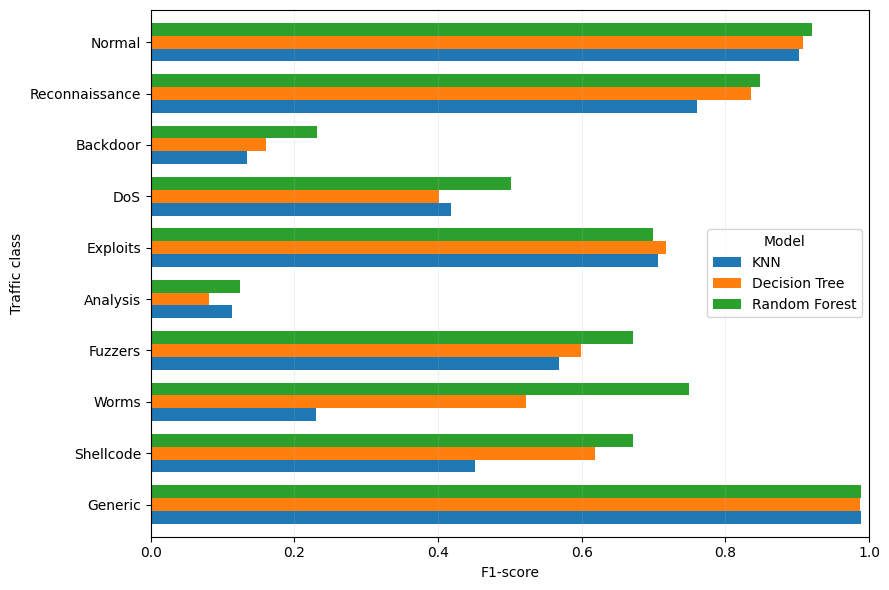

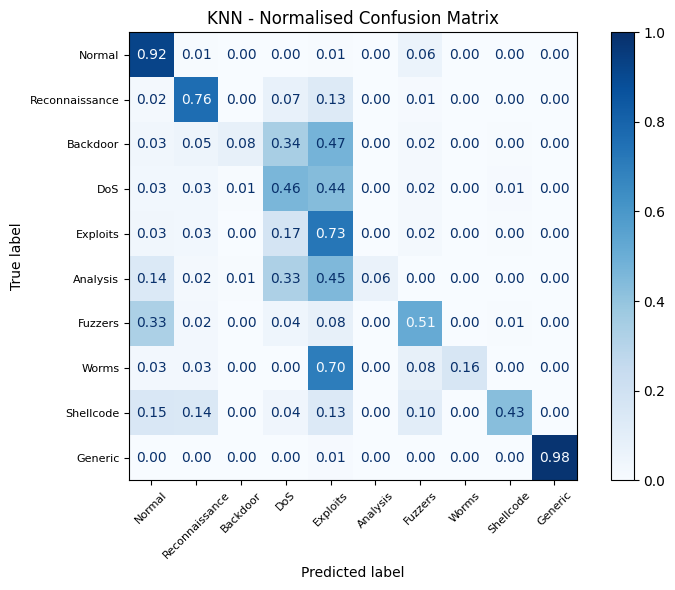

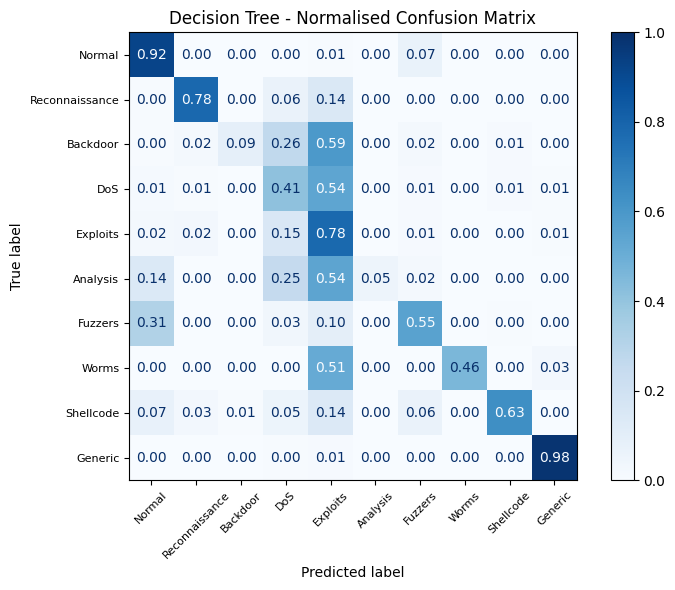

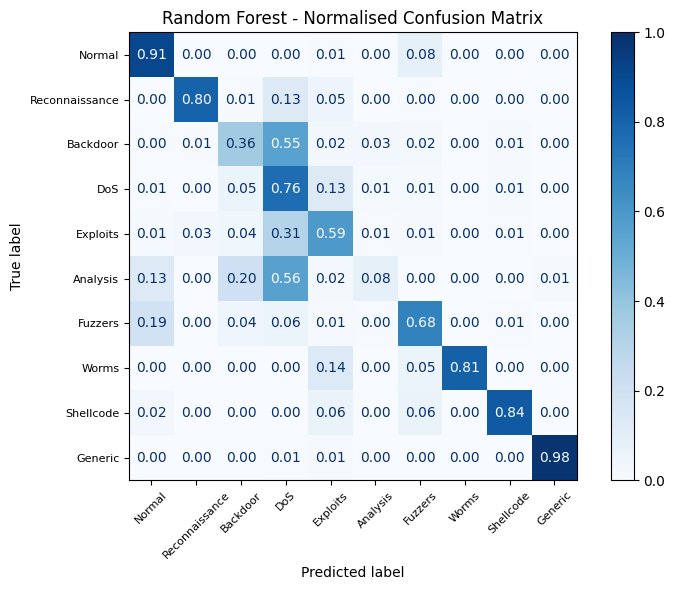


All figures saved to: C:\Users\nicol\Downloads\Assignment4_ML\assignment4_outputs


In [19]:

# Create and save final comparison figures
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

OUTPUT_DIR = Path("assignment4_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

class_names = [
    "Normal", "Reconnaissance", "Backdoor", "DoS",
    "Exploits", "Analysis", "Fuzzers", "Worms",
    "Shellcode", "Generic"
]

# Class-specific F1 comparison
f1_table = final_class_comparison.pivot(
    index="Class",
    columns="Model",
    values="F1"
)

f1_table = f1_table.loc[
    range(10), ["KNN", "Decision Tree", "Random Forest"]
]

f1_table.index = class_names

fig, ax = plt.subplots(figsize=(9, 6))

f1_table.iloc[::-1].plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.set_xlabel("F1-score")
ax.set_ylabel("Traffic class")
ax.set_xlim(0, 1)
ax.legend(title="Model")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "class_specific_f1.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "class_specific_f1.pdf",
    bbox_inches="tight"
)

plt.show()

# Normalised confusion matrices
model_predictions = {
    "KNN": knn_predictions,
    "Decision Tree": final_predictions["Decision Tree"],
    "Random Forest": final_predictions["Random Forest"]
}

for name, predictions in model_predictions.items():

    fig, ax = plt.subplots(figsize=(8, 6))

    display = ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=list(range(10)),
        display_labels=class_names,
        normalize="true",
        values_format=".2f",
        cmap="Blues",
        xticks_rotation=45,
        ax=ax
    )

    display.im_.set_clim(0, 1)

    ax.set_title(f"{name} - Normalised Confusion Matrix")
    ax.tick_params(axis="both", labelsize=8)

    plt.tight_layout()

    filename = name.lower().replace(" ", "_")

    fig.savefig(
        OUTPUT_DIR / f"{filename}_confusion.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}_confusion.pdf",
        bbox_inches="tight"
    )

    plt.show()

print("\nAll figures saved to:", OUTPUT_DIR.resolve())


In [20]:

# Save all experimental results and split information
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("assignment4_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

tables = {
    "baseline_comparison.csv": comparison,
    "class_weighting.csv": results,
    "leaf_size.csv": leaf_comparison,
    "feature_randomness.csv": feature_comparison,
    "number_of_trees.csv": tree_count_comparison,
    "cross_validation.csv": cv_df,
    "cv_summary.csv": cv_summary,
    "final_comparison.csv": final_comparison,
    "final_class_comparison.csv": final_class_comparison
}

for filename, table in tables.items():
    table.to_csv(
        OUTPUT_DIR / filename,
        index=(filename == "cv_summary.csv")
    )

# Preserve the exact original row indices used in each split
pd.DataFrame({
    "row_index": X_train.index
}).to_csv(OUTPUT_DIR / "train_indices.csv", index=False)

pd.DataFrame({
    "row_index": X_test.index
}).to_csv(OUTPUT_DIR / "test_indices.csv", index=False)

print("All experimental results saved.\n")

print("Saved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)


All experimental results saved.

Saved files:
baseline_comparison.csv
class_specific_f1.pdf
class_specific_f1.png
class_weighting.csv
cross_validation.csv
cv_summary.csv
Decision_Tree_confusion.csv
decision_tree_confusion.pdf
decision_tree_confusion.png
feature_randomness.csv
final_class_comparison.csv
final_comparison.csv
KNN_confusion.csv
knn_confusion.pdf
knn_confusion.png
leaf_size.csv
number_of_trees.csv
Random_Forest_confusion.csv
random_forest_confusion.pdf
random_forest_confusion.png
test_indices.csv
test_predictions.csv
train_indices.csv
